<a href="https://colab.research.google.com/github/dasmiq/cs6200-documents/blob/main/term_statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Working with Terms and Documents

This exercise starts off with term statistics computations and graphing. In the final section (for CS6200 students), you collect new documents to experiment with.

Read through this Jupyter notebook and fill in the parts marked with `TODO`.

## Sample Data

Start by looking at some sample data. We donwload the counts of terms in documents for the first one million tokens of a newswire collection.

In [1]:
# !wget -O ap201001.json.gz https://github.com/dasmiq/cs6200-documents/blob/main/ap201001.json.gz?raw=true
# !gunzip ap201001.json.gz

import gzip
import os
import urllib.request

AP_URL = 'https://github.com/dasmiq/cs6200-documents/blob/main/ap201001.json.gz?raw=true'
if not os.path.exists('ap201001.json'):
  with urllib.request.urlopen(AP_URL) as response:
    data = gzip.decompress(response.read())
  with open('ap201001.json', 'wb') as f:
    f.write(data)

We convert this file with one JSON record on each line to a list of dictionaries.

In [2]:
import json
rawfile = open('ap201001.json')
terms = [json.loads(line) for line in rawfile]

Here are the first ten records, showing the count of each term for each document and field. In this dataset, field only takes the values `body` or `title`.

In [3]:
terms[1:10]

[{'id': 'APW_ENG_20100101.0001', 'field': 'body', 'term': 'about', 'count': 1},
 {'id': 'APW_ENG_20100101.0001', 'field': 'body', 'term': 'abuse', 'count': 1},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'academy',
  'count': 1},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'accused',
  'count': 2},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'actress',
  'count': 1},
 {'id': 'APW_ENG_20100101.0001', 'field': 'body', 'term': 'ad', 'count': 1},
 {'id': 'APW_ENG_20100101.0001', 'field': 'body', 'term': 'after', 'count': 1},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'agenda',
  'count': 1},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'agreed',
  'count': 1}]

Each record has four fields:
* `id`, with the identifier for the document;
* `field`, with the region of the document containing a given term;
* `term`, with the lower-cased term; and
* `count`, with the number of times each term occurred in that field and document.

## Computing Term Statistics


If we look at the most frequent terms for a given document, we mostly see common function words, such as `the`, `and`, and `of`. Start exploring the dataset by computing some of these basic term statistics. You can make your life easier using data frame libraries such as `pandas`, core python libraries such as `collections`, or just simple list comprehensions.

Feel free to define helper functions in your code before computing the statistics we're looking for.

In [4]:
# TODO: Print the 10 terms from document APW_ENG_20100101.0001 with the highest count.

from collections import Counter, defaultdict

# One row per record: the same term can appear once for 'body' and once for 'title'
doc_terms = [t for t in terms if t['id'] == 'APW_ENG_20100101.0001']
print("Term | Field | Count")
for t in sorted(doc_terms, key=lambda t: t['count'], reverse=True)[:10]:
  print(t['term'], " | ", t['field'], " | ", t['count'])

Term | Field | Count
a  |  body  |  16
the  |  body  |  11
and  |  body  |  10
brooks  |  body  |  10
of  |  body  |  10
to  |  body  |  10
he  |  body  |  9
in  |  body  |  9
gomez  |  body  |  8
for  |  body  |  6


**Body and title kept separate.** Each record in the data is one term in one field of one document, so the same term can show up twice for a document: once in the body and once in the title. Each record is kept as it is instead of merging the two fields, which keeps the title and body counts visible separately. The downside is that a term's count in a document can be split across two rows. For this document all ten top terms come from the body. Ties are left in file order (e.g. "and", "brooks", "of" and "to" all have 10), so if several terms tie at the cut-off, which ones make the list is arbitrary.

In [5]:
# TODO: Print the 10 terms with the highest total count in the corpus.

# Total count = sum over all documents and both fields (body + title)
total_counts = Counter()
for t in terms:
  total_counts[t['term']] += t['count']

for term, count in total_counts.most_common(10):
  print(term, count)

the 62216
to 26931
in 25659
a 23383
of 22326
and 22125
said 10888
for 9716
on 9382
that 8942


**Collection totals add both fields.** For collection-wide counts, body and title counts are added together, since a word in a headline is still an occurrence of that word. This gives "the" a total of 62216, far ahead of every other term.

Raw counts may not be the most informative statistic. One common improvement is to use *inverse document frequency*, the inverse of the proportion of documents that contain a given term.

In [6]:
# TODO: Compute the number of distinct documents in the collection.
N = len({t['id'] for t in terms})

# TODO: Compute the number of distinct documents each term appears in
# and store in a dictionary.
df = dict()

# Set of ids used so a term in both the body and title of one document counts once
docs_with_term = defaultdict(set)
for t in terms:
  docs_with_term[t['term']].add(t['id'])
df = {term: len(ids) for term, ids in docs_with_term.items()}

print('N =', N)
print('Distinct terms:', len(df))

N = 2778
Distinct terms: 27556


**Document frequency counts documents and not records.** df is built from the set of document IDs each term appears in, so a term found in both the body and the title of the same document counts once. Counting records instead would inflate df for those terms and make them look more common (and less important) than they really are. N comes out to 2778 documents.

In [7]:
# TODO: Print the relative document frequency of 'the',
# i.e., the number of documents that contain 'the' divided by N.

print("Relative document frequency of 'the':", df['the'] / N)

Relative document frequency of 'the': 0.9704823614110871


Empricially, we usually see better retrieval results if we rescale term frequency (within documents) and inverse document frequency (across documents) with the log function. Let the `tfidf` of term _t_ in document _d_ be:
```
tfidf(t, d) = log(count(t, d) + 1) * log(N / df(t))
```

Later in the course, we will show a probabilistic derivation of this quantity based on smoothing language models.

In [8]:
import math

# TODO: Compute the tf-idf value for each term in each document.
# Take the raw term data and add a tfidf field to each record.
tfidf_terms = None

tfidf_terms = []

# tfidf(t, d) = log(count(t, d) + 1) * log(N / df(t)); copy each record so `terms` is unchanged
for t in terms:
  record = dict(t)
  record['tfidf'] = math.log(t['count'] + 1) * math.log(N / df[t['term']])
  tfidf_terms.append(record)

In [9]:
# TODO: Print the 20 term-document pairs with the highest tf-idf values.
for t in sorted(tfidf_terms, key=lambda t: t['tfidf'], reverse=True)[:20]:
  print(t['id'], t['field'], t['term'], t['count'], round(t['tfidf'], 4))

APW_ENG_20100103.0028 body guarani 24 23.2929
APW_ENG_20100105.0061 body nomination 95 22.5194
APW_ENG_20100105.0446 body methane 15 21.9852
APW_ENG_20100103.0015 body kheire 14 21.4734
APW_ENG_20100105.0014 body greyhound 14 21.4734
APW_ENG_20100107.0036 body shakespeare 18 21.307
APW_ENG_20100105.0061 body guild 28 20.6675
APW_ENG_20100106.0428 body shakespeare 16 20.5021
APW_ENG_20100102.0197 body elkhart 12 20.3387
APW_ENG_20100106.0075 body magna 12 20.3387
APW_ENG_20100106.1325 body sutton 20 19.9209
APW_ENG_20100104.0043 body tohti 11 19.704
APW_ENG_20100105.0014 body greyhounds 11 19.704
APW_ENG_20100107.0018 body krewe 11 19.704
APW_ENG_20100107.0928 body minhas 11 19.704
APW_ENG_20100105.0061 body golden 70 19.3026
APW_ENG_20100105.0061 body actors 26 19.2808
APW_ENG_20100107.0018 body pirate 20 19.2415
APW_ENG_20100103.0016 body punk 13 19.0971
APW_ENG_20100104.0108 body shiites 10 19.0141


**tf-idf details.** The natural log is used for both parts of the formula; changing the log base only rescales every value by the same factor, so the ranking stays the same. Each record is copied before the tfidf field is added, so the original `terms` list stays untouched and the cell can be re-run safely, at the cost of holding a second copy of the data in memory. The results show what idf is for: "the" appears in 97.0% of documents (0.9705), so log(N/df) is close to 0 and it effectively drops out, while the top pairs are rare names and topic words like guarani and nomination. The log on the count also flattens large counts: "nomination" appears 95 times but still ranks below "guarani" with 24.

## Plotting Term Distributions

Besides frequencies and tf-idf values within documents, it is often helpful to look at the distrubitions of word frequencies in the whole collection. In class, we talk about the Zipf distribution of word rank versus frequency and Heaps' Law relating the number of distinct words to the number of tokens.

We might examine these distributions to see, for instance, if an unexpectedly large number of very rare terms occurs, which might indicate noise added to our data.

In [10]:
# TODO: Compute a list of the distinct words in this collection and sort it in descending order of frequency.
# Thus frequency[0] should contain the word "the" and the count 62216.
frequency = []

frequency = total_counts.most_common()  # list of (word, count), highest count first
print(frequency[0])
print('Vocabulary size:', len(frequency))

('the', 62216)
Vocabulary size: 27556


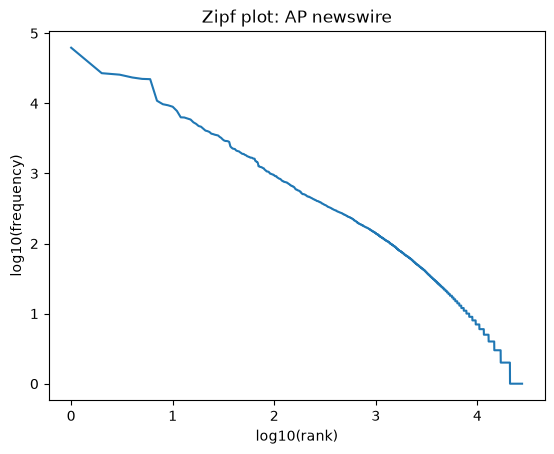

In [11]:
# TODO: Plot a graph of the log of the rank (starting at 1) on the x-axis,
# against the log of the frequency on the y-axis. You may use the matplotlib
# or other library.

import matplotlib.pyplot as plt

log_rank = [math.log10(r) for r in range(1, len(frequency) + 1)]
log_freq = [math.log10(count) for _, count in frequency]

plt.plot(log_rank, log_freq)
plt.xlabel('log10(rank)')
plt.ylabel('log10(frequency)')
plt.title('Zipf plot: AP newswire')
plt.show()

**Analysing the AP data against the Zipf plot.**
- **Single point, then a plateau:** "the" sits alone at the top (62216, about 4.8 on the log scale). Ranks 2–6 (to, in, a, of, and) are almost flat because these five function words all have similar counts, between 26931 and 22125. Zipf's law (rank × frequency ≈ constant) would have them dropping much faster, so the very top of the distribution does not fit the law well.
- **Sudden drop at rank 7:** "said" (10888) has less than half the count of "and". This is where the list switches from grammar words that almost every sentence needs to the first content word, and "said" being that word is typical of newswire.
- **Straight middle:** From roughly rank 10 to rank 1,000 the curve is close to a straight line, slightly flatter than a slope of −1. This is the range where Zipf's law fits best.
- **Steps at the bottom right:** At low frequencies many words share exactly the same count (every word seen 3 times, 2 times, 1 time), so each count shows up as a flat step. The steps get wider as the count gets smaller because more words share it, and the last, longest step at 0 is all the words seen exactly once.
- **Bend below the line in the tail:** Just before the steps, the curve drops below the straight line, so there are fewer rare words than Zipf's law would predict. This is likely because newswire is edited text with consistent spelling, so it produces few one-off words.

In [12]:
# TODO: Compute the number of tokens in the corpus.
# Remember to count each occurrence of each word. For instance, the 62,216
# instances of "the" will all count here.
ntokens = 0

ntokens = sum(count for _, count in frequency)
print('Number of tokens:', ntokens)

Number of tokens: 1000000


In [13]:
# TODO: Compute the proportion of tokens made up by the top 10 most
# frequent words.

top10_tokens = sum(count for _, count in frequency[:10])
print('Proportion of tokens from top 10 words:', top10_tokens / ntokens)

Proportion of tokens from top 10 words: 0.221568


In [14]:
# TODO: Compute the proportion of tokens made up by the words that occur
# exactly once in this collection.

once_tokens = sum(count for _, count in frequency if count == 1)
print('Proportion of tokens from words occurring once:', once_tokens / ntokens)

Proportion of tokens from words occurring once: 0.006641


## Acquiring New Documents (CS6200)

This section is required for students in CS6200 and worth up to 10 points extra credit for students in CS4220.

For this assignment so far, you've worked with data that's already been extracted, tokenized, and counted. In this final section, you'll explore acquiring new data.

One common way of acquiring data is through application programming interfaces (APIs) to various databases. The Library of Congress's [_Chronicling America_](https://www.loc.gov/collections/chronicling-america/about-this-collection/) site aggregates digitized US newspapers from the past two hundred years, such as the [_Milwaukee Leader_](https://www.loc.gov/resource/sn83045293/1926-09-26/ed-1/) from 100 years ago.

You can use [the API](https://libraryofcongress.github.io/data-exploration/loc.gov%20JSON%20API/Chronicling_America/README.html) to retrieve JSON data listing all issues of the _Milwaukee Leader_ from 1926: https://www.loc.gov/item/sn83045293/?st=calendar&year=1926&fo=json

Note the list in the `issue_data` field. For example, here is the record for the January 17, 1926, issue: https://www.loc.gov/item/sn83045462/1920-04-21/ed-1/. To get the information structured in JSON from the API, we append `?fo=json`, i.e.: https://www.loc.gov/item/sn83045462/1920-04-21/ed-1/?fo=json

In that issue record, you'll see links to data about individual pages in various data formats, such as JPEG, PDF, XML, and plain text, which is what we want here: https://tile.loc.gov/text-services/word-coordinates-service?segment=/service/ndnp/dlc/batch_dlc_ixtl_ver01/data/sn83045462/00280656732/1920042101/0366.xml&format=alto_xml&full_text=1

This plain text was transcribed from the digital images of the microfilm of old pages using optical character recognition (OCR) models, and so contains errors.

Your task is to acquire and analyze the issues of the _Milwaukee Leader_ from the month of September, 1926, i.e., the issues with a date field that starts with `1926-09`. This should be about the same amount of data as the million words from the Associated Press you analyzed in the last section.

Write code that calls the _Chronicling America_ API to download and extract the text from the _Milwaukee Leader_ from September 1926. You can use the `json` library from above and any other libraries you wish to fetch data from URLs. As you would when working with any production API, you may need to limit your rate of requests.

In [15]:
# TODO: Data acquisition code here.

import os
import time
import requests

CALENDAR_URL = 'https://www.loc.gov/item/sn83045293/?st=calendar&year=1926&fo=json'
CACHE_FILE = 'milwaukee_1926_09.json'  # saved edition list and page text, so re-runs skip the download
DELAY = 2  # seconds to wait after each request, to stay under loc.gov's rate limits

def get_json(url, retries=5):
  # GET a URL and return its JSON; on rate limiting, server errors or timeouts, wait and retry
  for attempt in range(retries):
    try:
      r = requests.get(url, timeout=60)
      if r.status_code == 200:
        time.sleep(DELAY)
        return r.json()
      retry_after = r.headers.get('Retry-After', '')
      wait = int(retry_after) if retry_after.isdigit() else 30
      print(f'  HTTP {r.status_code} for {url}; waiting {wait}s')
    except requests.RequestException as e:
      wait = 30
      print(f'  {type(e).__name__} for {url}; waiting {wait}s')
    time.sleep(wait)
  raise RuntimeError(f'Giving up on {url}')

# Cache: {'issue_urls': [edition URLs], issue_url: [{'id': page_id, 'text': page_text}, ...]},
# saved after the edition list is fetched and after every edition
cache = {}
if os.path.exists(CACHE_FILE):
  with open(CACHE_FILE) as f:
    cache = json.load(f)

# 1. List every edition of every issue dated September 1926.
#    The issue list is under calendar_data -> issue_data. Some Saturdays have a
#    second edition (Saturday Magazine Section) with different content, so it is kept.
#    The list is saved in the cache, so loc.gov is only asked for it once.
if 'issue_urls' not in cache:
  calendar = get_json(CALENDAR_URL)
  cache['issue_urls'] = [edition['url']
                         for issue in calendar['calendar_data']['issue_data']
                         if issue['date'].startswith('1926-09')
                         for edition in issue['urls']]
  with open(CACHE_FILE, 'w') as f:
    json.dump(cache, f)
issue_urls = cache['issue_urls']
print(len(issue_urls), 'editions in September 1926')

# 2. For each edition not saved yet, get its list of pages, then each page's OCR plain text.
for issue_url in issue_urls:
  if issue_url in cache:
    continue
  issue = get_json(issue_url + '?fo=json')
  issue_pages = []
  for seq, page_files in enumerate(issue['resources'][0]['files'], start=1):
    text_url = next((f['fulltext_service'] for f in page_files if 'fulltext_service' in f), None)
    if text_url is None:
      continue
    text_json = get_json(text_url)  # {xml_path: {'full_text': ...}}
    issue_pages.append({'id': issue_url.split('/item/')[1] + f'seq-{seq}',
                        'text': next(iter(text_json.values()))['full_text']})
  cache[issue_url] = issue_pages
  with open(CACHE_FILE, 'w') as f:
    json.dump(cache, f)
  print(issue_url, '->', len(issue_pages), 'pages')

# One document = one page
pages = [page for issue_url in issue_urls for page in cache[issue_url]]
print('Total pages (documents):', len(pages))


29 editions in September 1926
https://www.loc.gov/item/sn83045293/1926-09-01/ed-1/ -> 14 pages
https://www.loc.gov/item/sn83045293/1926-09-02/ed-1/ -> 14 pages
https://www.loc.gov/item/sn83045293/1926-09-03/ed-1/ -> 14 pages
https://www.loc.gov/item/sn83045293/1926-09-04/ed-1/ -> 16 pages
https://www.loc.gov/item/sn83045293/1926-09-04/ed-2/ -> 6 pages
https://www.loc.gov/item/sn83045293/1926-09-05/ed-1/ -> 16 pages
https://www.loc.gov/item/sn83045293/1926-09-08/ed-1/ -> 14 pages
https://www.loc.gov/item/sn83045293/1926-09-09/ed-1/ -> 14 pages
https://www.loc.gov/item/sn83045293/1926-09-10/ed-1/ -> 14 pages
https://www.loc.gov/item/sn83045293/1926-09-11/ed-1/ -> 16 pages
https://www.loc.gov/item/sn83045293/1926-09-11/ed-2/ -> 6 pages
https://www.loc.gov/item/sn83045293/1926-09-12/ed-1/ -> 14 pages
https://www.loc.gov/item/sn83045293/1926-09-14/ed-1/ -> 14 pages
https://www.loc.gov/item/sn83045293/1926-09-15/ed-1/ -> 14 pages
https://www.loc.gov/item/sn83045293/1926-09-16/ed-1/ -> 14 pag

**Data acquisition process.**
- **29 editions:** Every edition dated 1926-09 is included, including the Saturday Magazine Section that appears as a second edition on Saturdays (6 pages each). It has different content, not a repeat of the regular paper.
- **One page = one document (392 pages):** Pages are how the API provides the text, and a page is closer in size to a short AP article than a whole issue would be. The downside is that an article continuing onto another page gets split into two documents; that only matters for per-document counts, not for totals over the whole collection.
- **Slow on purpose:** The API limits how fast requests can be made, so the code waits 2 seconds after each request and retries after a pause if the server says to slow down. The download takes longer, but it does not get blocked.
- **Saved to a file:** The text is saved to `milwaukee_1926_09.json` after each edition, along with the list of editions, so re-running the notebook loads from the file instead of downloading anything again, and an interrupted download picks up where it stopped. The cost is an extra data file next to the notebook, and the saved copy will not reflect any later corrections on the site.

Write code to tokenize the text and count the resulting terms in each document. Since this data comes from automatically transcribing printed pages, some words may be hyphenated across line breaks. There is more than one right way to tokenize this data, so add comments to your code documenting your choices.

In [16]:
# TODO: Tokenization code here.

import re

def tokenize(text):
  # 1. Re-join words hyphenated across a line break ("Approv-\ned" -> "Approved").
  #    OCR also splits many words across lines with no hyphen ("con\nflict"); these
  #    can't be detected reliably, so the fragments are left in as OCR noise.
  text = re.sub(r'-[ \t]*\n[ \t]*', '', text)
  # 2. Lower-case everything, as in the AP data.
  text = text.lower()
  # 3. Turn curly apostrophes into straight ones, so "didn’t" matches AP's "didn't".
  text = text.replace('\u2019', "'").replace('\u2018', "'")
  # 4. A token is a run of letters, optionally joined by apostrophes ("didn't", "china's").
  #    Digits, hyphens, quotes, dashes and other symbols act as separators, matching the
  #    AP data, whose terms contain only letters and apostrophes.
  return re.findall(r"[a-z]+(?:'[a-z]+)*", text)

# Term counts for each document (page)
ml_counts = {page['id']: Counter(tokenize(page['text'])) for page in pages}

# Collection-wide counts, sorted by frequency (same format as `frequency` for AP)
ml_total = Counter()
for counts in ml_counts.values():
  ml_total.update(counts)
ml_frequency = ml_total.most_common()
ml_ntokens = sum(count for _, count in ml_frequency)

print('Documents (pages):', len(ml_counts))
print('Number of tokens:', ml_ntokens)
print('Vocabulary size:', len(ml_frequency))
print('Top 10 words:', ml_frequency[:10])
print('Any AP term with a digit:', any(c.isdigit() for w in df for c in w))

Documents (pages): 392
Number of tokens: 1548001
Vocabulary size: 71128
Top 10 words: [('the', 85814), ('of', 46876), ('and', 38752), ('to', 33476), ('a', 30100), ('in', 27584), ('for', 14631), ('is', 12413), ('that', 10905), ('at', 10358)]
Any AP term with a digit: False


**Tokenization choices.** The goal is to tokenize the same way as the AP data, so the comparison is fair. 
- **Digits dropped:** This loses numbers such as dates and prices, which are common in a 1926 paper full of ads, but the AP terms contain no numbers, so keeping them would make the two vocabularies not comparable.
- **Line-break hyphens re-joined, other hyphens split:** "Approv-" followed by "ed" on the next line becomes "approved". Words broken across lines without a hyphen are left split, because re-joining them would need a guess (e.g. join if the result is a known word) that could also glue two real words together. The simpler rule leaves some fragments that get counted as rare words.

Plot a graph of the log rank against log frequency for your collection, as you did for the sample collection above.

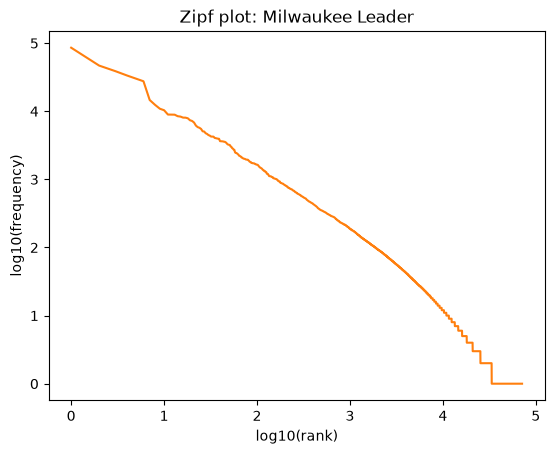

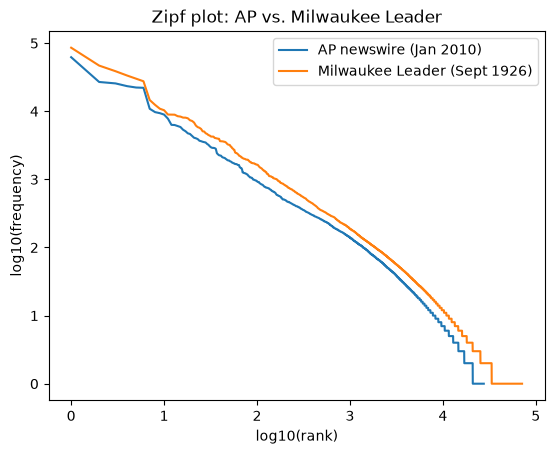

In [17]:
# TODO: Plotting code here.
ml_log_rank = [math.log10(r) for r in range(1, len(ml_frequency) + 1)]
ml_log_freq = [math.log10(count) for _, count in ml_frequency]

# 1. Milwaukee Leader on its own
plt.figure()
plt.plot(ml_log_rank, ml_log_freq, color='tab:orange')
plt.xlabel('log10(rank)')
plt.ylabel('log10(frequency)')
plt.title('Zipf plot: Milwaukee Leader')
plt.show()

# 2. Milwaukee Leader on the same axes as AP, for comparison
plt.figure()
plt.plot(log_rank, log_freq, label='AP newswire (Jan 2010)')
plt.plot(ml_log_rank, ml_log_freq, label='Milwaukee Leader (Sept 1926)')
plt.xlabel('log10(rank)')
plt.ylabel('log10(frequency)')
plt.title('Zipf plot: AP vs. Milwaukee Leader')
plt.legend()
plt.show()

**Analysing data from the Milwaukee Leader on the plots.**
- **Top:** "the" (85814) is followed by "of" (46876), close to half, and the next few function words keep falling steadily instead of forming a flat plateau like the one in the AP plot.
- **Same drop at rank 7:** The count roughly halves from "in" (27584) to "for" (14631), just like AP's drop from "and" to "said". In both collections the six most common function words are far ahead of everything else.
- **Straight middle:** Like AP, the middle ranks follow a roughly straight line, so Zipf's law fits this part of both collections.
- **Very long flat tail:** The vocabulary is 71128 words, so the curve runs much further right, and the bottom steps, especially the last one at frequency 1, are much wider than in AP. A tail this long is the "unexpectedly large number of very rare terms" that the notebook points to as a sign of noise in the data.

**Comparing the two.** The Milwaukee Leader curve sits above AP at every rank, partly just because it has more tokens (1548001 vs. 1000000), which raises every count. Through the top and the middle the two shapes are very similar, so the real difference is on the right: the AP curve ends at its 27556th word, while the Milwaukee Leader keeps going for tens of thousands more ranks of rare words.

In [18]:
# TODO: Compute the proportion of tokens made up by the top 10 most
# frequent words in this collection.

ml_top10_tokens = sum(count for _, count in ml_frequency[:10])
print('Proportion of tokens from top 10 words:', ml_top10_tokens / ml_ntokens)

Proportion of tokens from top 10 words: 0.20084547749000162


In [19]:
# TODO: Compute the proportion of tokens made up by the words that occur
# exactly once in this collection.

ml_once_tokens = sum(count for _, count in ml_frequency if count == 1)
print('Proportion of tokens from words occurring once:', ml_once_tokens / ml_ntokens)

print('Words occurring once:', len([1 for _, count in ml_frequency if count == 1]), 'of', len(ml_frequency))
print('Examples of words occurring once:', [w for w, c in ml_frequency if c == 1][:40])

Proportion of tokens from words occurring once: 0.024344299519186357
Words occurring once: 37685 of 71128
Examples of words occurring once: ['mermann', 'voight', "in'our", 'tionallv', 'dissatisfac', 'incred', 'politico', 'excepted', 'mulgating', 'autono', 'entitles', 'outlived', 'vstem', 'syndieal', 'busts', 'ruptcies', 'credi', 'ote', 'tobe', 'octopus', 'cmpared', 'urgescongress', 'unionizing', 'teamster', 'capitalize', 'pulchritudinous', 'olgo', 'milin', 'zinski', 'tooted', 'siesta', 'tvon', 'zvill', 'oivned', 'roose', 'subverts', 'festations', 'pennited', 'shoefid', 'ausrust']


What do you observe about the differences between the distributions of the Associated Press and Milwaukee Leader collections?

**TODO: Describe the differences between the AP and the Milwaukee Leader word frequency distributions. Describe some possible reasons for these differences.**

**Differences**

- **Most frequent words:** The top of both distributions looks almost the same. The top 10 words make up 22.2% of AP tokens (0.221568) and 20.1% of Milwaukee Leader tokens (0.2008), and they are mostly the same function words (the, of, and, to, a, in, for, that). The one that stands out is "said" at #7 in AP, which makes sense for newswire since it is constantly quoting people; the Milwaukee Leader has "is" and "at" there instead. So the most common words do not really depend on the source or the era.
- **Rare words:** This is where the two collections really split. In the Milwaukee Leader, words that occur exactly once make up 2.43% of tokens (0.0243) compared to 0.66% for AP (0.006641), over 3.5 times as much. And 37685 of its 71128 distinct words show up only once, which is more than half of its vocabulary.
- **Vocabulary size:** The Milwaukee Leader has about 1.5 times the tokens of AP (1548001 vs. 1000000) but over 2.5 times the distinct words (71128 vs. 27556). So it is not just a bigger collection; it has far more distinct "words" for its size.
- **Zipf plots:** Both curves are roughly a straight line in the middle, as Zipf's law predicts, and both bend at the very top and bottom. The Milwaukee Leader curve starts higher, goes further right, and has a much longer flat part at frequency 1. That is the same long tail of one-off words from above, showing up on the plot.

**Reasons**

Printing some of the Milwaukee Leader words that occur only once shows where the extra rare words come from. Most of them are not real words, and they fall into a few groups:

- **OCR errors:** The text comes from OCR of old printed pages, so misread letters turn normal words into new ones that only show up once, e.g. vstem (system), zvill (will), pennited (permitted), tionallv. Every misreading adds another "word" to the vocabulary. OCR also sometimes drops spaces, giving one-off tokens like urgescongress and tobe.
- **Words split across lines:** Many words are broken across line breaks without a hyphen, so the tokenizer counts the pieces as separate words (dissatisfac, ruptcies, festations, mulgating). Only words with a hyphen at the line break were re-joined, since without one there is no reliable way to tell a split word from two real words.
- **Not just collection size:** Heaps' law says vocabulary grows roughly with the square root of the number of words (β ≈ 0.5), so 1.5 times the tokens should only give about 1.2 times the vocabulary, not 2.5 times. That rules out size as the main reason and points back to the noise.
- **Content and preparation:** The Milwaukee Leader is a 1926 paper with ads, local news and names, written differently from 2010 newswire, so some of the new words are real. The AP data was also already extracted, tokenized and counted before this assignment, so it is much cleaner to start with. The function words at the top stay the same because every English text uses them heavily.